# Lab 8 rerun on Parkinson's midbrain — GSE157783 (Smajić et al., 2022, *Brain*)
Purpose: redo the Lab 8 cell-type expression step on Parkinson's tissue so PD2 stays on the Part I targets.
Run cell by cell in Colab. **Stop after Cell 3 and check the printed output before going on** — file names and column names below are placeholders until confirmed.

In [1]:

!pip -q install scanpy
import pandas as pd, numpy as np, scanpy as sc, scipy.sparse as sp, os
sc.settings.set_figure_params(dpi=110, frameon=False)
os.makedirs('figures', exist_ok=True)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
/tmp/ipykernel_1681/2825158426.py:3: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=110, frameon=False)


In [2]:
!curl -s https://ftp.ncbi.nlm.nih.gov/geo/series/GSE157nnn/GSE157783/suppl/ | grep -o 'href="[^"]*"' | sed 's/href=//;s/"//g'

/geo/series/GSE157nnn/GSE157783/
GSE157783_IPDCO_hg_midbrain_UMI.tar.gz
GSE157783_IPDCO_hg_midbrain_cell.tar.gz
GSE157783_IPDCO_hg_midbrain_genes.tar.gz
https://www.hhs.gov/vulnerability-disclosure-policy/index.html


In [3]:
BASE = 'https://ftp.ncbi.nlm.nih.gov/geo/series/GSE157nnn/GSE157783/suppl/'
files = ['GSE157783_IPDCO_hg_midbrain_UMI.tar.gz',
         'GSE157783_IPDCO_hg_midbrain_cell.tar.gz',
         'GSE157783_IPDCO_hg_midbrain_genes.tar.gz']
os.makedirs('gse157783', exist_ok=True)
for f in files:
    !wget -nc -P gse157783 {BASE + f}
    !tar -xzf gse157783/{f} -C gse157783
!ls -lhR gse157783

--2026-11-24 19:21:14--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE157nnn/GSE157783/suppl/GSE157783_IPDCO_hg_midbrain_UMI.tar.gz
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.13, 130.14.250.31, 2607:f220:41e:250::13, ...
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.13|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 129256807 (123M) [application/x-gzip]
Saving to: ‘gse157783/GSE157783_IPDCO_hg_midbrain_UMI.tar.gz’

GSE157783_IPDCO_hg_ 100%[===================>] 123.27M  27.6MB/s    in 5.0s    

2026-11-24 19:21:19 (24.7 MB/s) - ‘gse157783/GSE157783_IPDCO_hg_midbrain_UMI.tar.gz’ saved [129256807/129256807]

--2026-11-24 19:21:43--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE157nnn/GSE157783/suppl/GSE157783_IPDCO_hg_midbrain_cell.tar.gz
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.13, 130.14.250.31, 2607:f220:41e:250::13, ...
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.

In [4]:
d = 'gse157783/'
for f in ['IPDCO_hg_midbrain_UMI.tsv', 'IPDCO_hg_midbrain_genes.tsv', 'IPDCO_hg_midbrain_cell.tsv']:
    print(f'\n=== {f}')
    !head -n 4 {d}{f} | cut -c1-250
    !head -n 2 {d}{f} | awk -F'\t' '{print "  fields in line", NR, ":", NF}'
    !wc -l {d}{f}


=== IPDCO_hg_midbrain_UMI.tsv
AAACCCACACATTGTG-1_1	AAACCCAGTAAGATTG-1_1	AAACGAACACCGCTGA-1_1	AAACGAAGTGCTTATG-1_1	AAACGAATCAATCTCT-1_1	AAACGAATCCAGTGCG-1_1	AAACGCTAGACTCTTG-1_1	AAACGCTAGCGACCCT-1_1	AAACGCTCACCTATCC-1_1	AAACGCTGTCTAACGT-1_1	AAACGCTTCCTCACCA-1_1	AAACGCTTCTCGTTTA-1_
1	2	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	1	0	0	0	1	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	2	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	1	0	0	0	1	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	
0	0	0	0	0	0	0	0	0	1	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	
0	3	1	0	0	0	0	0	1	0	1	0	0	0	0	1	0	0	0	0	0	0	0	1	0	0	2	0	0	0	0	0	0	0	0	0	1	1	1	0	0	0	1	0	0	0	0	0	0	0	0	2	0	0	0	2	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	1	2	0	0	1	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	0	

**Before Cell 4:** from the peek, decide orientation. If the counts index looks like gene symbols (e.g. `MIR1302-2HG`, `SNCA`) and columns look like cell barcodes, set `GENES_ARE_ROWS = True`. Also fill in the metadata column names.

In [5]:
targets = ['LMNA','PBXIP1','SNCA','MAP4K4','WDR1','KTN1','BAG3','NDUFAF2',
           'MAPT','PAM','SH3GL2','PPP6R2','CHL1','FYN','STK39']   # Module 2 top 15
markers = {
    'Dopaminergic neurons': ['TH','SLC6A3','SLC18A2'],
    'Neurons (general)':    ['RBFOX3','SNAP25','GAD1'],
    'Astrocytes':           ['GFAP','AQP4'],
    'Microglia':            ['CSF1R','P2RY12'],
    'Oligodendrocytes':     ['MOBP','MOG'],
    'OPCs':                 ['PDGFRA'],
    'Endothelial':          ['CLDN5'],
}
keep_genes = set(targets) | {g for v in markers.values() for g in v}
print(len(targets), 'targets;', len(keep_genes), 'genes to keep')

15 targets; 29 genes to keep


In [6]:
!pip -q install mygene
import mygene
d = 'gse157783/'
genes = pd.read_csv(d + 'IPDCO_hg_midbrain_genes.tsv', sep='\t')
ens_pos = {e: i for i, e in enumerate(genes['gene'])}        # Ensembl ID -> data-row position

res = mygene.MyGeneInfo().querymany(sorted(keep_genes), scopes='symbol',
                                    fields='ensembl.gene', species='human')
sym2ens = {}
for r in res:
    e = r.get('ensembl')
    if not e: continue
    ids = [x['gene'] for x in (e if isinstance(e, list) else [e])]
    hits = [i for i in ids if i in ens_pos]
    if hits: sym2ens[r['query']] = hits[0]
pos2sym = {ens_pos[e]: s for s, e in sym2ens.items()}
print(f'mapped {len(sym2ens)} of {len(keep_genes)}; not found:', sorted(keep_genes - set(sym2ens)))

INFO:biothings.client:querying 1-29 ...
INFO:biothings.client:Finished.


mapped 29 of 29; not found: []


In [7]:
kept, totals, offset = {}, None, 0
for chunk in pd.read_csv(d + 'IPDCO_hg_midbrain_UMI.tsv', sep='\t', chunksize=1000, dtype=np.int32):
    s = chunk.sum(axis=0).values.astype(np.int64)
    totals = s if totals is None else totals + s
    for pos in range(offset, offset + len(chunk)):
        if pos in pos2sym:
            kept[pos2sym[pos]] = chunk.iloc[pos - offset].values
    offset += len(chunk)
    if offset % 5000 == 0: print(offset, 'genes read')
barcodes = chunk.columns
print('gene rows read:', offset, '(expected', len(genes), ') | cells:', len(barcodes))

sub = pd.DataFrame(kept, index=barcodes)
adata = sc.AnnData(X=sp.csr_matrix(sub.values.astype(np.float32)),
                   obs=pd.DataFrame(index=barcodes), var=pd.DataFrame(index=sub.columns))
adata.obs['total_counts'] = totals

meta = pd.read_csv(d + 'IPDCO_hg_midbrain_cell.tsv', sep='\t').set_index('barcode')
assert len(barcodes) == len(meta), 'cell count mismatch — paste this error to Claude'
adata = adata[meta.index].copy()
adata.obs['cell_type'] = meta['cell_ontology'].astype('category').values
adata.obs['donor']     = meta['patient'].astype(str).values
adata.obs['condition'] = np.where(adata.obs['donor'].str.startswith('PD'), 'PD', 'Control')
print(adata.obs.groupby(['condition', 'donor']).size())
print(adata.obs['cell_type'].value_counts())

5000 genes read
10000 genes read
15000 genes read
20000 genes read
25000 genes read
gene rows read: 26737 (expected 26737 ) | cells: 41435
condition  donor
Control    C1       3753
           C2       4358
           C3       2047
           C4       4199
           C5       2318
           C6       5758
PD         PD1      1943
           PD2      5925
           PD3      3345
           PD4      2083
           PD5      5706
dtype: int64
cell_type
Oligodendrocytes     21268
Astrocytes            4708
Microglia             3903
Excitatory            3037
OPCs                  2754
Endothelial cells     1723
Inhibitory            1548
Pericytes             1229
Ependymal              536
GABA                   535
CADPS2+ neurons        120
DaNs                    74
Name: count, dtype: int64


In [8]:
X = adata.X.multiply(1e4 / adata.obs['total_counts'].values[:, None])
adata.X = sp.csr_matrix(np.log1p(X.toarray()))

/tmp/ipykernel_1681/742545759.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(adata, {k: [g for g in v if g in adata.var_names] for k, v in markers.items()},


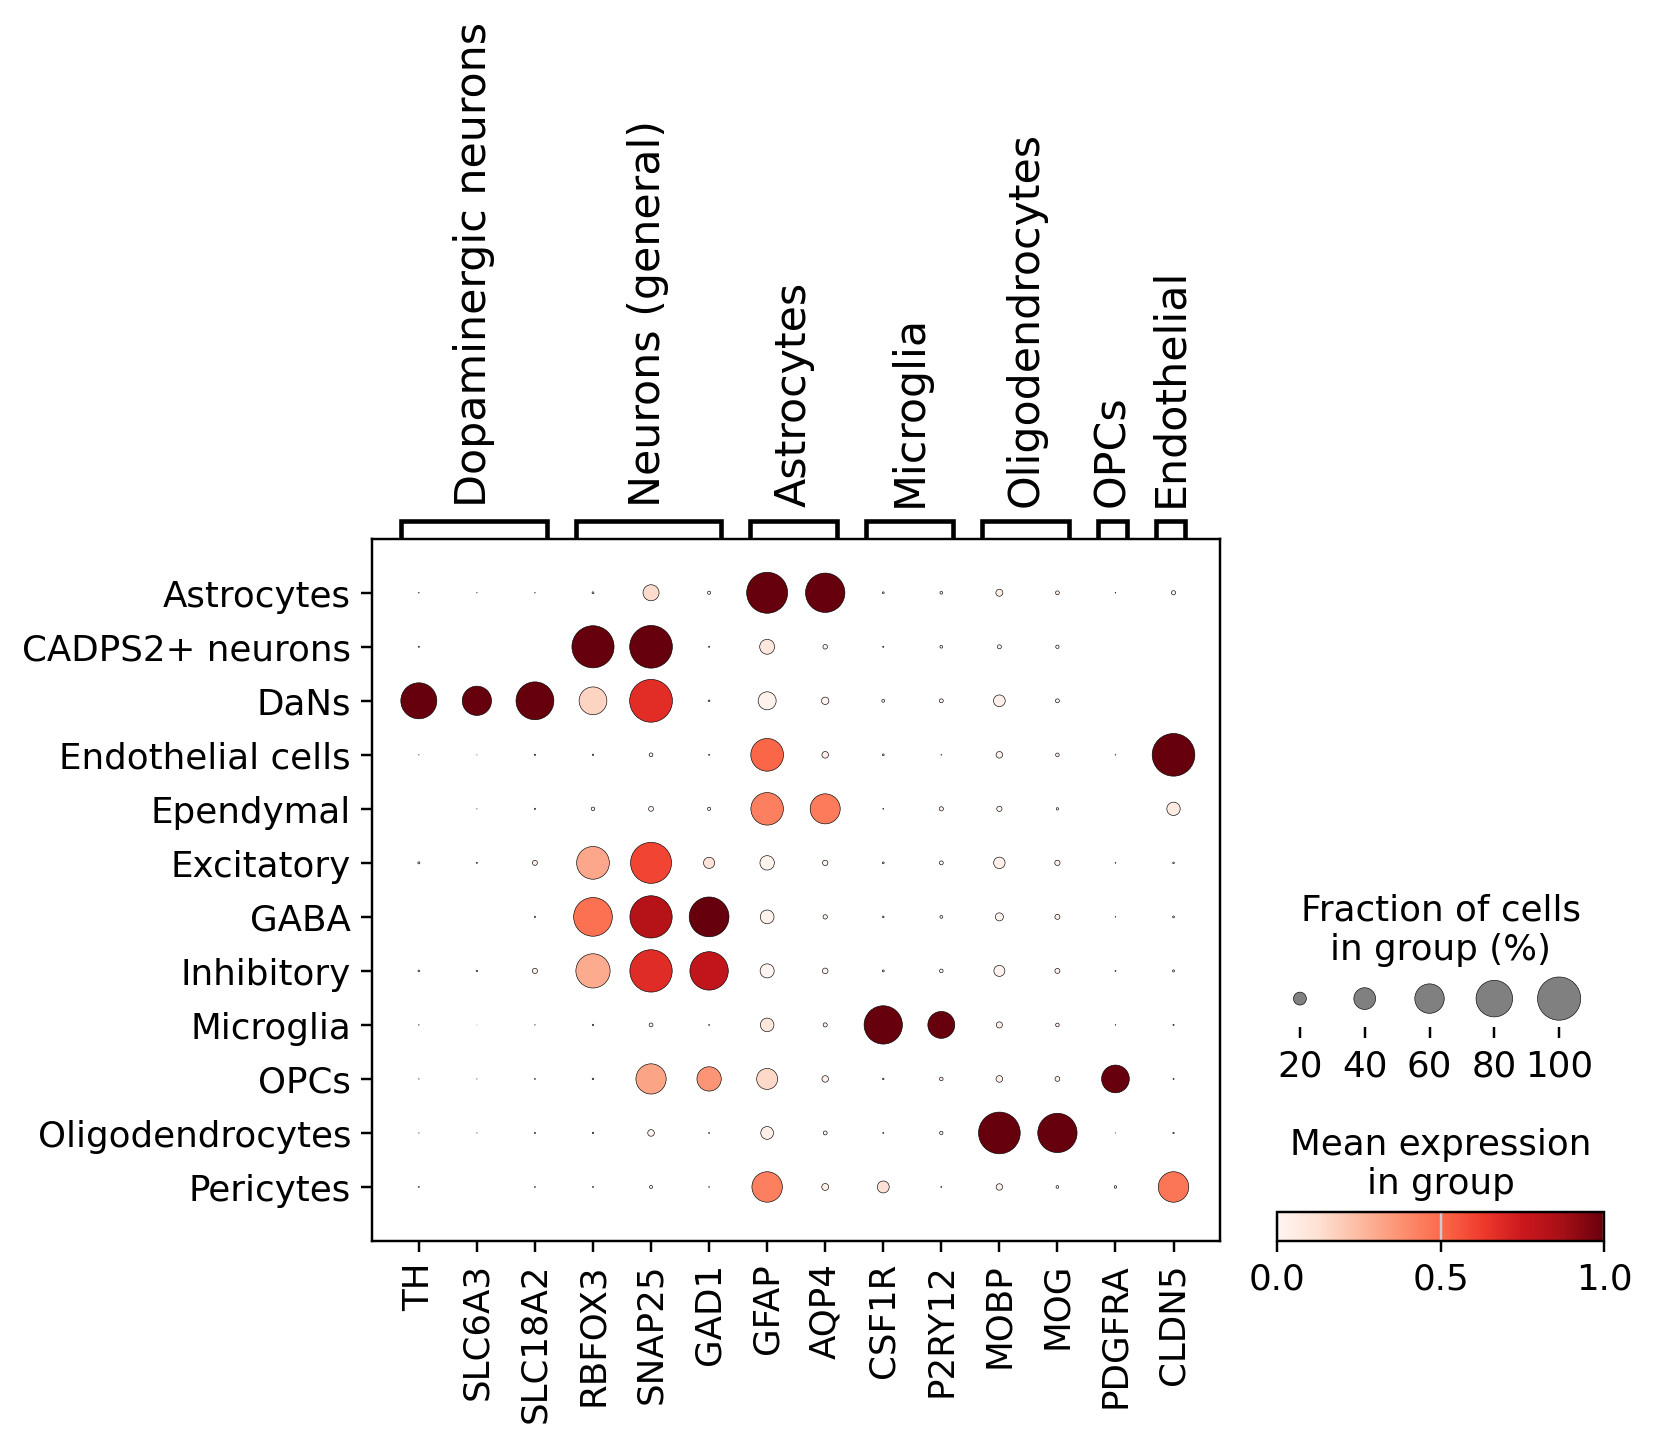

In [9]:
sc.pl.dotplot(adata, {k: [g for g in v if g in adata.var_names] for k, v in markers.items()},
              groupby='cell_type', standard_scale='var', save='_gse157783_marker_check.png')

/tmp/ipykernel_1681/416014845.py:3: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(adata, t, groupby='cell_type', standard_scale='var',


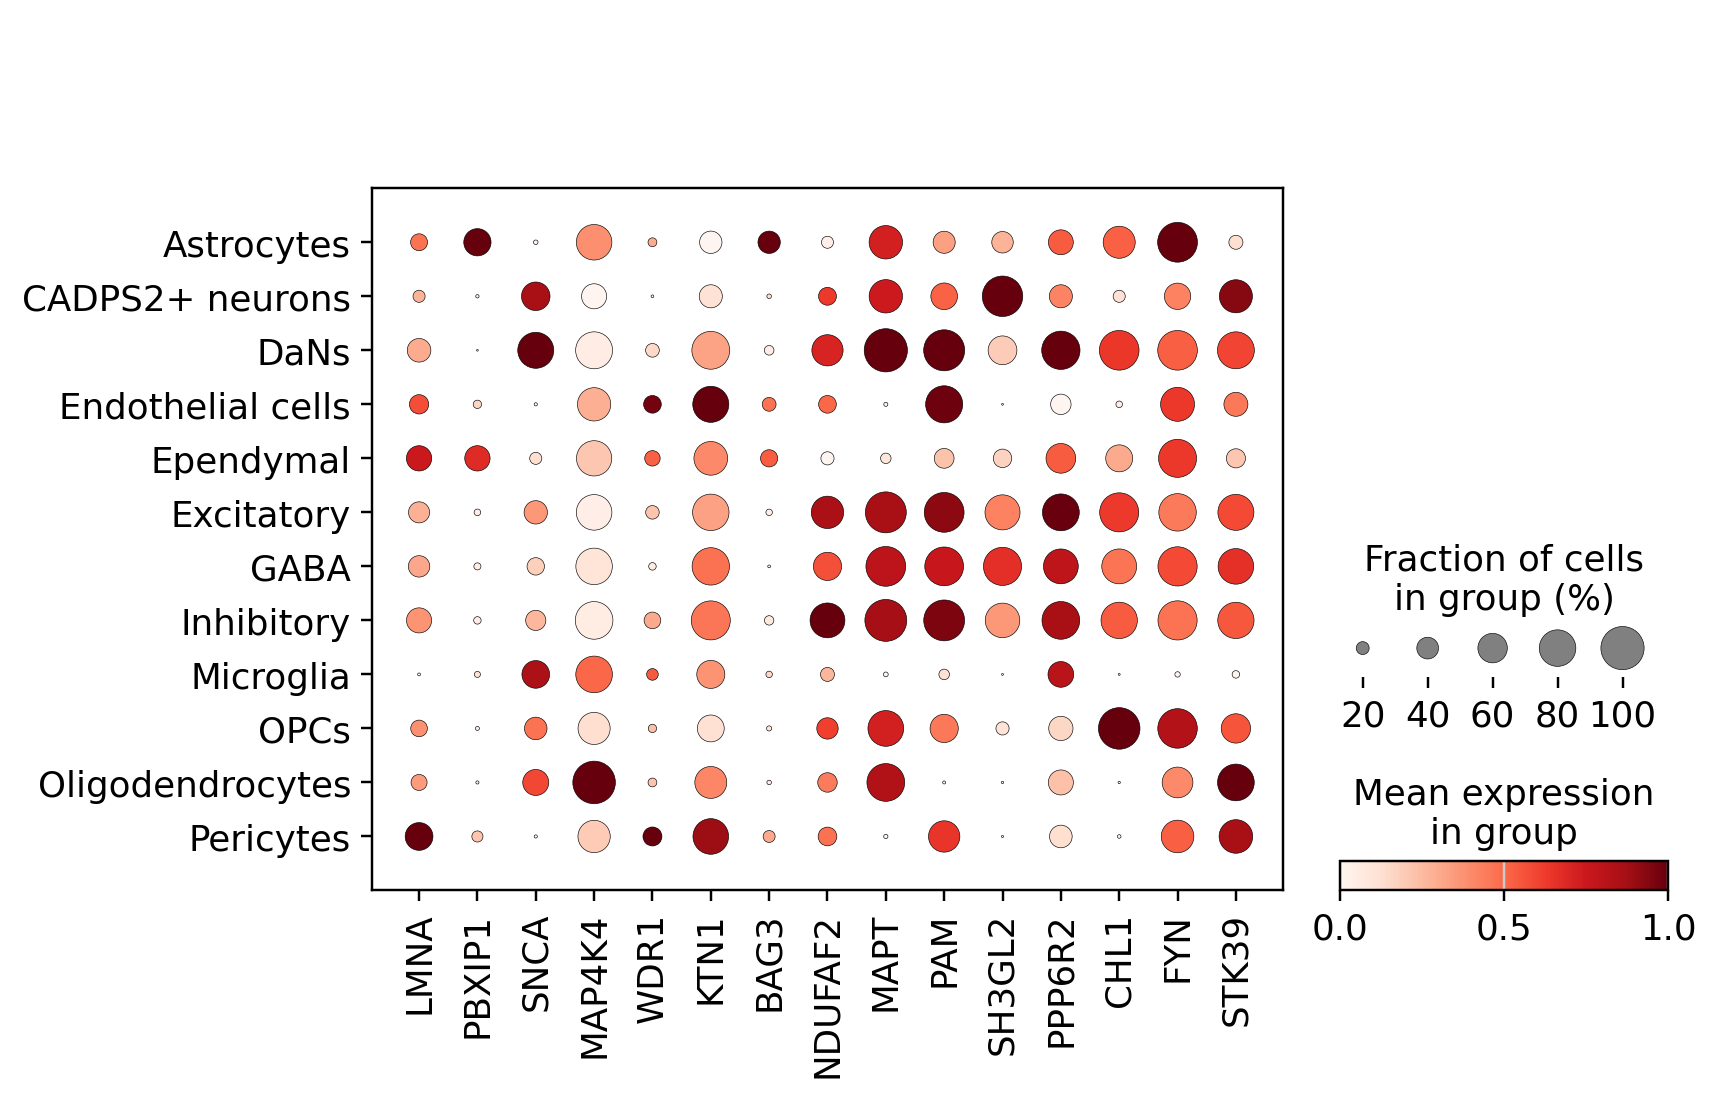

In [10]:
t = [g for g in targets if g in adata.var_names]
sc.pl.dotplot(adata, t, groupby='cell_type', standard_scale='var',
              save='_gse157783_targets_by_celltype.png')

In [11]:
adata.obs['celltype_condition'] = (adata.obs['cell_type'].astype(str) + ' | '
                                   + adata.obs['condition'].astype(str)).astype('category')

In [12]:
rows = []
for (ct, cond), idx in adata.obs.groupby(['cell_type','condition'], observed=True).groups.items():
    Xs = adata[idx, t].X.toarray()
    for j, g in enumerate(t):
        rows.append({'cell_type': ct, 'condition': cond, 'gene': g, 'n_cells': len(idx),
                     'mean_log_expr': Xs[:, j].mean(), 'pct_expressing': 100 * (Xs[:, j] > 0).mean()})
summary = pd.DataFrame(rows)
summary.to_csv('celltype_expression_targets_GSE157783.csv', index=False)
print(summary.pivot_table(index='gene', columns='cell_type', values='pct_expressing', aggfunc='mean').round(1))

cell_type  Astrocytes  CADPS2+ neurons   DaNs  Endothelial cells  Ependymal  \
gene                                                                          
BAG3             41.1              2.6   12.3               23.2       29.5   
CHL1             67.0             41.9   87.5                8.6       51.9   
FYN              89.8             59.0   87.9               72.9       85.6   
KTN1             41.7             54.7   81.6               79.3       70.5   
LMNA             28.2             25.6   43.8               33.7       50.4   
MAP4K4           77.1             57.3   79.6               70.8       75.9   
MAPT             70.9             68.8  100.0                4.2       14.4   
NDUFAF2          18.1             15.8   61.6               30.7       19.8   
PAM              41.4             59.4   92.6               81.7       35.3   
PBXIP1           53.9              1.7    1.6               11.2       50.1   
PPP6R2           48.2             54.7   84.3       

In [13]:
!zip -r lab8_rerun_outputs.zip figures celltype_expression_targets_GSE157783.csv
from google.colab import files
files.download('lab8_rerun_outputs.zip')

  adding: figures/ (stored 0%)
  adding: figures/dotplot__gse157783_marker_check.png (deflated 9%)
  adding: figures/dotplot__gse157783_targets_by_celltype.png (deflated 6%)
  adding: celltype_expression_targets_GSE157783.csv (deflated 62%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
adata.obs['celltype_condition'] = (adata.obs['cell_type'].astype(str) + ' | '
                                   + adata.obs['condition'].astype(str)).astype('category')